# 10 선정된 센서 49개의 전체 기간 시계열

1. 입력 준비 — `sensor_15`, `sensor_50`, `sensor_51`을 제외한 49개 센서, 전체 기간 선형보간(05와 동일)
2. 센서별 PNG 저장 — `figures/pump_selected_sensors/sensor_XX.png` (49장)
3. 한 장짜리 개요 — `figures/pump_selected_sensors/overview_all_sensors.png`

02 노트북은 원본 52개 센서를 결측 포함 상태로 그렸습니다. 이 노트북은 **최종 전처리(05)와 같은
데이터**, 즉 제외 후 남은 49개 센서를 전체 기간 시간 기준 선형보간한 값을 그리고, 그 위에 60분
이동평균(진한 선), 고장 시작(빨간 선), 회복 구간(붉은 띠), 선형보간으로 메운 구간(주황 띠, 60분 이상만)을
함께 표시합니다. 센서마다 단위가 달라 y축은 센서별로 맞춥니다.

## 1. 입력 준비

05 노트북과 같은 방식으로 49개 센서를 전체 기간 시간 기준 선형보간합니다(`interpolate(method="time")`).
관측값은 그대로 두고 비어 있던 자리만 채웁니다. 원본에서 비어 있던 자리는 `missing` 표에 남겨 그림에서
보간 구간을 표시하는 데 씁니다. 이동평균 창은 60분입니다.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd()
project_root = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "src" / "pump_features.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("kkobugi 저장소 또는 notebooks 폴더에서 실행하세요.")
sys.path.insert(0, str(project_root))

from src.pump_missingness_audit import MINUTE
from src.plot_style import use_korean_font
from src.pump_missingness_audit import default_source, read_sensor_data
from src.pump_features import EXCLUDED_SENSORS, failure_starts

print("그래프 글꼴:", use_korean_font())
figure_dir = project_root / "figures/pump_selected_sensors"
figure_dir.mkdir(parents=True, exist_ok=True)

MA_WINDOW = 60  # 이동평균 창(분)

source = default_source()
raw = read_sensor_data(source)
timestamps = pd.to_datetime(raw["timestamp"], errors="raise")
if raw.empty or timestamps.isna().any() or not timestamps.diff().iloc[1:].eq(MINUTE).all():
    raise ValueError("원본의 시각이 비어 있지 않고 1분 간격인지 확인하세요.")
index = pd.DatetimeIndex(timestamps, name="timestamp")
sensors = [column for column in raw if column.startswith("sensor_") and column not in EXCLUDED_SENSORS]
observed = raw[sensors].astype("float64").set_axis(index)
missing = observed.isna()
values = observed.interpolate(method="time", limit_area="inside")
if values.isna().any().any():
    raise ValueError("선형보간 후 결측이 남아 있습니다.")
np.testing.assert_array_equal(values.to_numpy()[~missing.to_numpy()], observed.to_numpy()[~missing.to_numpy()])
moving_average = values.rolling(MA_WINDOW, min_periods=1).mean()
status = raw["machine_status"].set_axis(index).rename("machine_status")
starts = failure_starts(status)

# 회복 구간(RECOVERING 연속 행)의 시작·끝 위치
recovering = status.eq("RECOVERING").to_numpy()
edges = np.flatnonzero(np.diff(np.r_[False, recovering, False]))
recovery_runs = list(zip(edges[::2], edges[1::2]))

print(f"센서 {len(sensors)}개 (제외: {', '.join(EXCLUDED_SENSORS)}) · {len(index):,}행 · "
      f"선형보간 {int(missing.to_numpy().sum()):,}개 · 고장 {len(starts)}건 · 회복 구간 {len(recovery_runs)}개 · "
      f"이동평균 {MA_WINDOW}분")

그래프 글꼴: NanumGothic


센서 49개 (제외: sensor_15, sensor_50, sensor_51) · 220,320행 · 선형보간 31,854개 · 고장 7건 · 회복 구간 7개 · 이동평균 60분


## 2. 센서별 PNG 저장

그림 하나에 한 센서. 위쪽 큰 패널에서 옅은 선이 선형보간한 1분 값, 진한 선이 60분 이동평균입니다.
아래 얇은 띠는 원본에서 비어 있던 분(결측)의 위치입니다. 제목 아래 요약에 결측 건수와 최장 결측 길이를
적습니다. 60분 이상 연속으로 보간한 구간은 위쪽 패널에도 주황 띠로 표시해 직선이 실제 값이 아니라 보간
값임을 알 수 있게 합니다.

findfont: Failed to find font weight bold for NanumGothic, now using 600.


49장 저장 → figures/pump_selected_sensors/


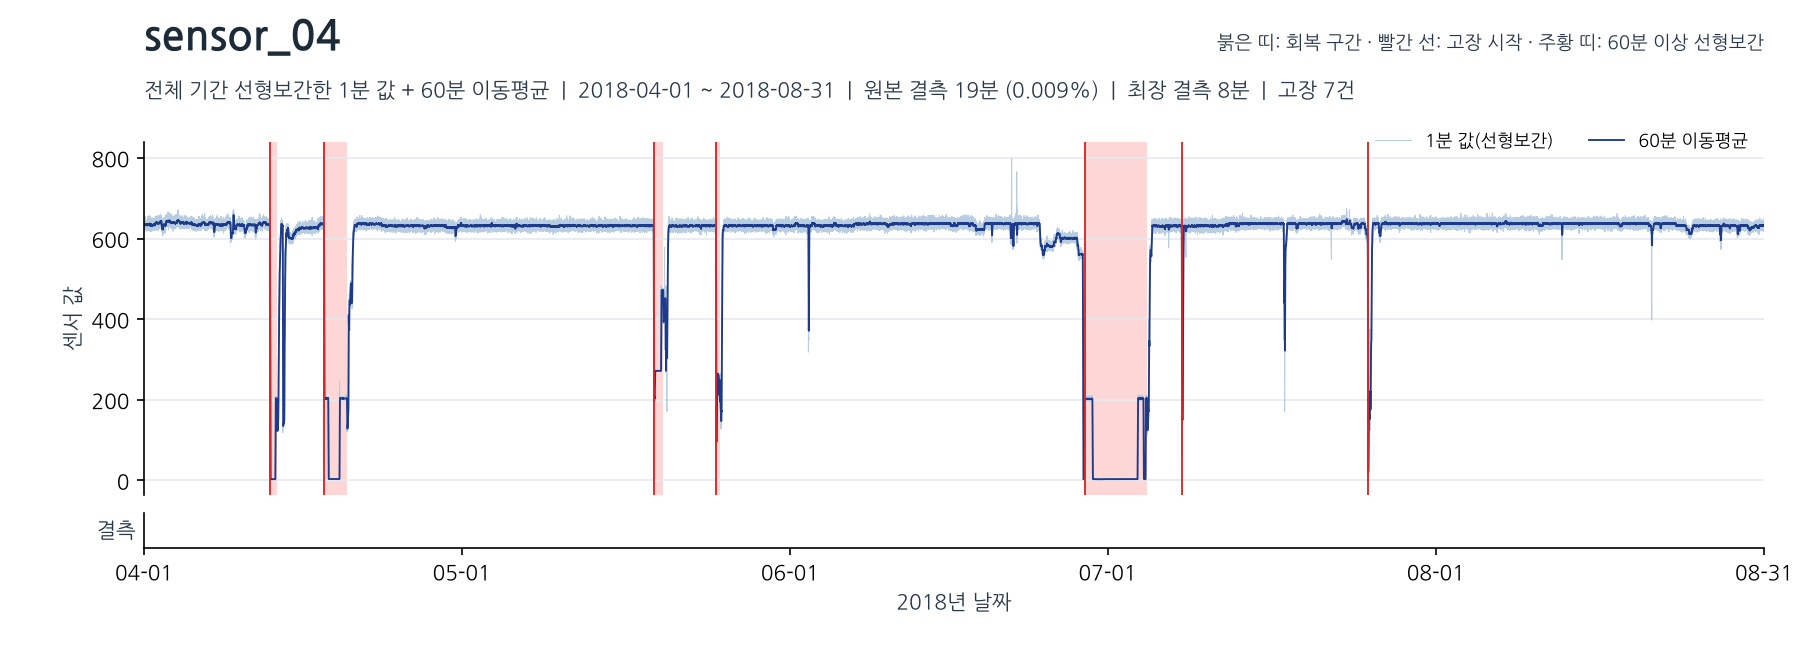

In [ ]:
LINE, MA, FILL, RECOVER, FAIL, GRID, INK = "#b8cde0", "#1e3a8a", "#f59e0b", "#fca5a5", "#dc2626", "#e5eaf0", "#28384a"
minutes = np.arange(len(index))
month_ticks = pd.date_range(index[0].normalize(), index[-1], freq="MS")
month_ticks = pd.DatetimeIndex([index[0], *month_ticks[(month_ticks > index[0])], index[-1]]).unique()
tick_positions = (month_ticks - index[0]) / MINUTE
tick_labels = [t.strftime("%m-%d") for t in month_ticks]
failure_positions = (starts - index[0]) / MINUTE


def missing_runs_of(sensor):
    flags = missing[sensor].to_numpy()
    edges = np.flatnonzero(np.diff(np.r_[False, flags, False]))
    return list(zip(edges[::2], edges[1::2]))


def save_sensor_figure(sensor):
    series = values[sensor].to_numpy()
    smoothed = moving_average[sensor].to_numpy()
    runs = missing_runs_of(sensor)
    lengths = [end - start for start, end in runs]
    missing_count = int(missing[sensor].sum())
    longest = max(lengths) if lengths else 0

    fig, (trace, band) = plt.subplots(
        2, 1, figsize=(12, 4.3), sharex=True, gridspec_kw={"height_ratios": [10, 1]},
    )
    fig.subplots_adjust(left=.08, right=.98, bottom=.15, top=.78, hspace=.09)
    fig.text(.08, .925, sensor, fontsize=20, fontweight="bold", color="#1d2b39")
    fig.text(.08, .85,
             f"전체 기간 선형보간한 1분 값 + {MA_WINDOW}분 이동평균  |  {index[0]:%Y-%m-%d} ~ {index[-1]:%Y-%m-%d}"
             f"  |  원본 결측 {missing_count:,}분 ({100 * missing_count / len(index):.3f}%)"
             f"  |  최장 결측 {longest:,}분  |  고장 {len(starts)}건",
             fontsize=10, color=INK)

    for start, end in recovery_runs:
        trace.axvspan(start - .5, end - .5, color=RECOVER, alpha=.45, linewidth=0)
    for start, end in runs:
        if end - start >= 60:
            trace.axvspan(start - .5, end - .5, color=FILL, alpha=.35, linewidth=0)
    trace.plot(minutes, series, color=LINE, linewidth=.5, label="1분 값(선형보간)")
    trace.plot(minutes, smoothed, color=MA, linewidth=.9, label=f"{MA_WINDOW}분 이동평균")
    for position in failure_positions:
        trace.axvline(position, color=FAIL, linewidth=.9)
    trace.set_ylabel("센서 값", color=INK)
    handles, labels = trace.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(.98, .82), ncol=2, fontsize=8.5, frameon=False)
    trace.grid(axis="y", color=GRID)
    trace.set_xlim(0, len(index) - 1)

    for start, end in runs:
        band.axvspan(start - .5, end - .5, color=FILL, linewidth=0)
    band.set_yticks([])
    band.set_ylabel("결측", rotation=0, ha="right", va="center", color=INK)
    band.set_xticks(tick_positions, tick_labels)
    band.set_xlabel("2018년 날짜", color=INK)
    for axis in (trace, band):
        for spine in ("top", "right"):
            axis.spines[spine].set_visible(False)
    trace.spines["bottom"].set_visible(False)
    trace.tick_params(axis="x", length=0)

    fig.text(.98, .925, "붉은 띠: 회복 구간 · 빨간 선: 고장 시작 · 주황 띠: 60분 이상 선형보간",
             fontsize=9, color=INK, ha="right")
    target = figure_dir / f"{sensor}.png"
    fig.savefig(target, dpi=150)
    plt.close(fig)
    return target


saved = [save_sensor_figure(sensor) for sensor in sensors]
print(f"{len(saved)}장 저장 → {figure_dir.relative_to(project_root).as_posix()}/")
display(Image(filename=str(figure_dir / "sensor_04.png"), width=900))

## 3. 한 장짜리 개요

49개 센서를 한 그림에 작은 패널로 모아 전체 흐름을 한눈에 봅니다. 옅은 선이 1분 값, 진한 선이 60분
이동평균이며, 고장 시작은 빨간 선, 회복 구간은 붉은 띠입니다. 값은 패널마다 자체 범위로 그립니다. 세부
확인은 2절의 센서별 그림을 봅니다.

findfont: Failed to find font weight bold for NanumGothic, now using 600.


저장 figures/pump_selected_sensors/overview_all_sensors.png


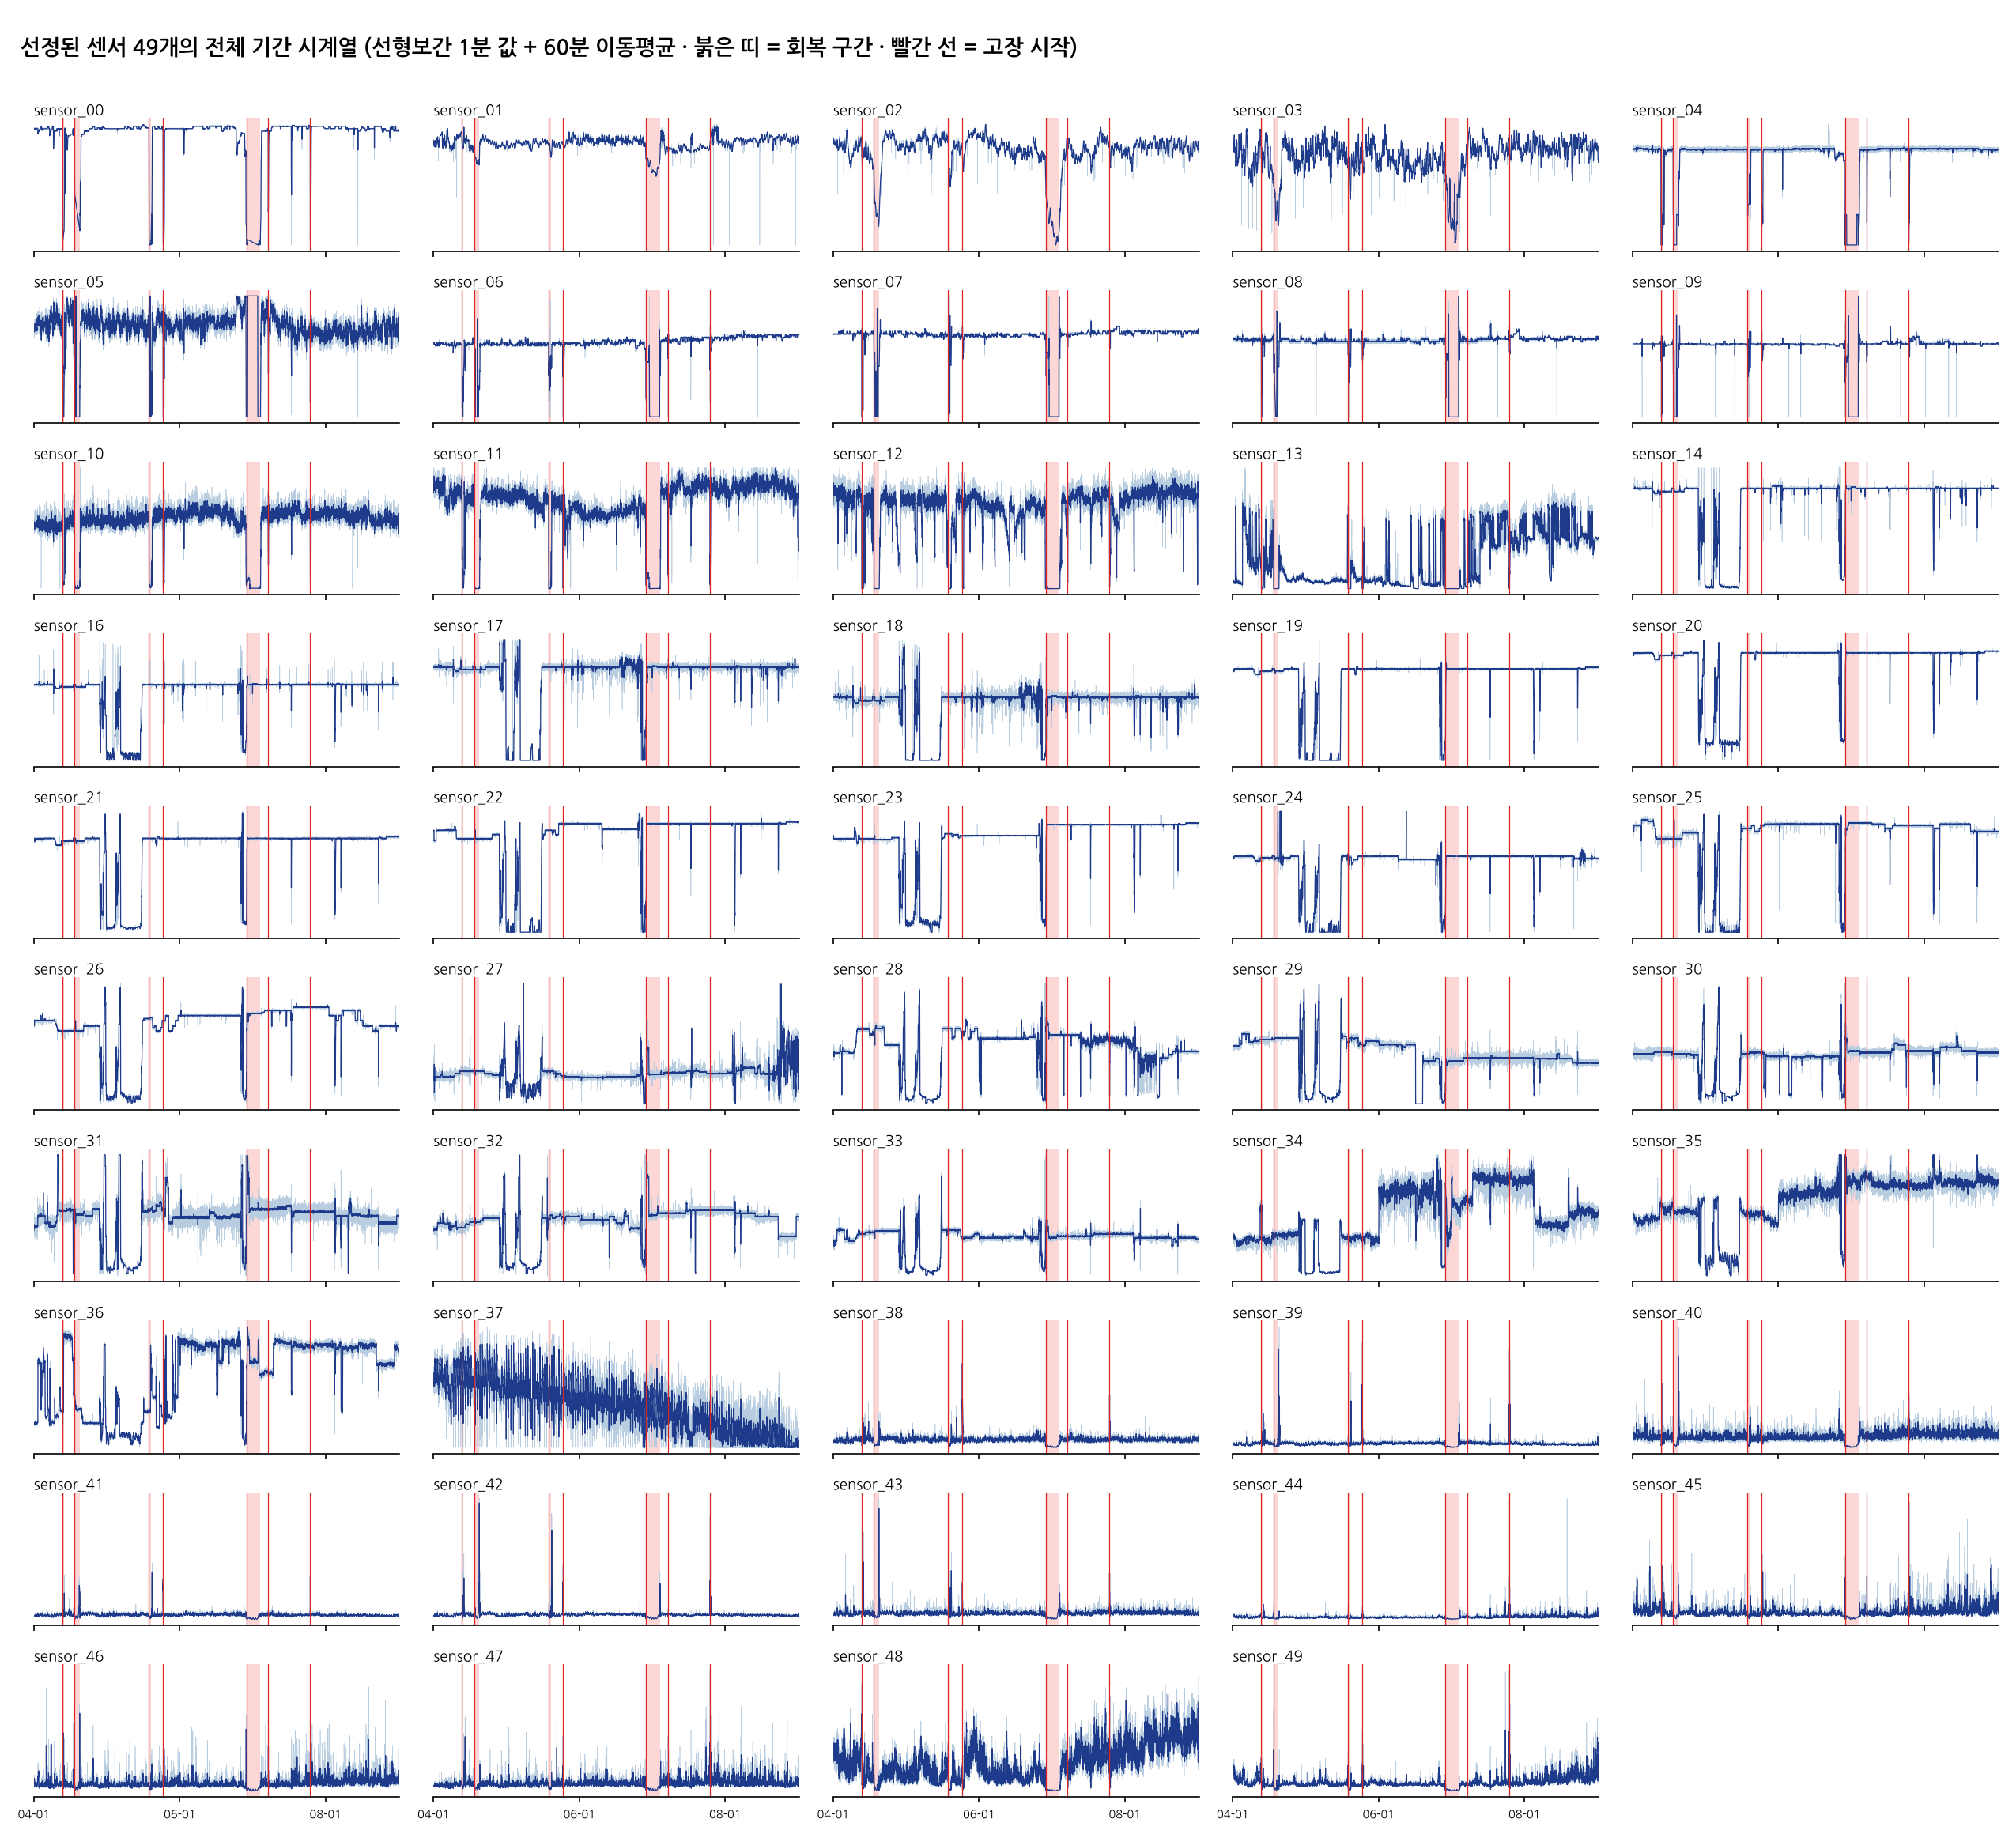

In [ ]:
columns_per_row = 5
rows = int(np.ceil(len(sensors) / columns_per_row))
fig, axes = plt.subplots(rows, columns_per_row, figsize=(3.4 * columns_per_row, 1.55 * rows), sharex=True)
for ax, sensor in zip(axes.flat, sensors):
    for start, end in recovery_runs:
        ax.axvspan(start - .5, end - .5, color=RECOVER, alpha=.45, linewidth=0)
    ax.plot(minutes, values[sensor].to_numpy(), color=LINE, linewidth=.3)
    ax.plot(minutes, moving_average[sensor].to_numpy(), color=MA, linewidth=.6)
    for position in failure_positions:
        ax.axvline(position, color=FAIL, linewidth=.6)
    ax.set_title(sensor, loc="left", fontsize=9, pad=2)
    ax.set_yticks([])
    ax.set_xlim(0, len(index) - 1)
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
for ax in axes.flat[len(sensors):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xticks(tick_positions[::2], tick_labels[::2], fontsize=7)
fig.suptitle(f"선정된 센서 49개의 전체 기간 시계열 (선형보간 1분 값 + {MA_WINDOW}분 이동평균 · 붉은 띠 = 회복 구간 · 빨간 선 = 고장 시작)",
             x=.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, .975))
overview_path = figure_dir / "overview_all_sensors.png"
fig.savefig(overview_path, dpi=150)
plt.close(fig)
print(f"저장 {overview_path.relative_to(project_root).as_posix()}")
display(Image(filename=str(overview_path), width=1000))